<a href="https://colab.research.google.com/github/gallegoshernandezcarlosmihael01/practica9y12/blob/main/ManualPracticas12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Actividad 1. Instalar e importar librerías**

In [ ]:
%pip install gymnasium numpy pandas matplotlib

In [ ]:
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

semilla = 42
rng = np.random.default_rng(semilla)

# **Actividad 2. Crear entorno**

In [ ]:
env = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=False,
    render_mode="ansi"
)

estado, info = env.reset(seed=semilla)

n_estados = env.observation_space.n
n_acciones = env.action_space.n

print("Estados:", n_estados)
print("Acciones:", n_acciones)
print(env.render())

Estados: 16
Acciones: 4

SFFF
FHFH
FFFH
HFFG



# **Actividad 3. Tabla Q**

In [ ]:
tabla_q = np.zeros(
    (n_estados, n_acciones)
)

print(tabla_q)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


# **Actividad 4. Hiperparámetros**

In [ ]:
alpha = 0.8
gamma = 0.95

epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.999

episodios = 10000
max_pasos = 100

recompensas = []
pasos_por_episodio = []
historial_epsilon = []

# **Actividad 5. Estrategia ε-greedy**

In [ ]:
def seleccionar_accion(
    estado,
    tabla_q,
    epsilon,
    rng
):

    if rng.random() < epsilon:
        accion = int(
            rng.integers(n_acciones)
        )

    else:
        accion = int(
            np.argmax(
                tabla_q[estado]
            )
        )

    return accion

# **Actividad 6. Entrenamiento Q-Learning**

In [ ]:
for episodio in range(episodios):

    estado, info = env.reset(
        seed=semilla + episodio
    )

    recompensa_total = 0
    pasos_realizados = 0

    for paso in range(max_pasos):

        accion = seleccionar_accion(
            estado,
            tabla_q,
            epsilon,
            rng
        )

        nuevo_estado, recompensa, terminado, truncado, info = env.step(accion)

        fin = terminado or truncado

        q_actual = tabla_q[
            estado,
            accion
        ]

        if fin:
            objetivo = recompensa

        else:
            mejor_q_futuro = np.max(
                tabla_q[nuevo_estado]
            )

            objetivo = (
                recompensa +
                gamma * mejor_q_futuro
            )

        tabla_q[
            estado,
            accion
        ] = (
            q_actual +
            alpha * (
                objetivo - q_actual
            )
        )

        estado = nuevo_estado

        recompensa_total += recompensa
        pasos_realizados = paso + 1

        if fin:
            break

    recompensas.append(
        recompensa_total
    )

    pasos_por_episodio.append(
        pasos_realizados
    )

    historial_epsilon.append(
        epsilon
    )

    epsilon = max(
        epsilon_min,
        epsilon * epsilon_decay
    )

print("Entrenamiento terminado")
print("Epsilon final:", epsilon)

Entrenamiento terminado
Epsilon final: 0.05


# **Actividad 7. Evolución del aprendizaje**

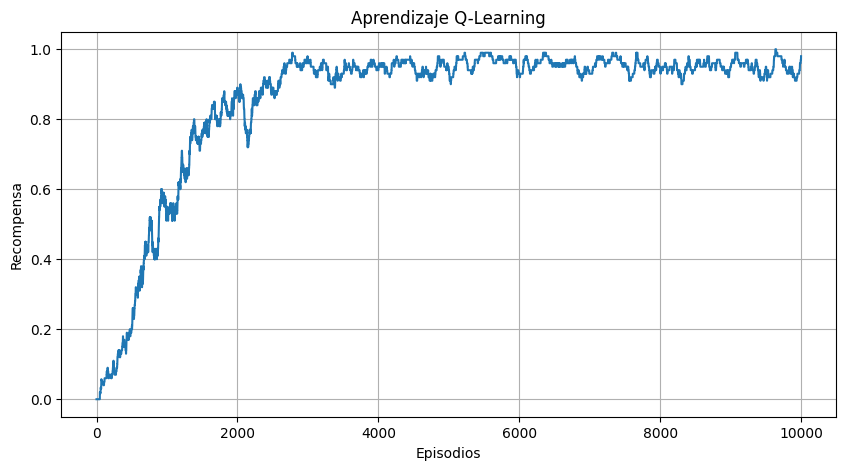

In [ ]:
serie = pd.Series(recompensas)

media_movil = serie.rolling(
    100,
    min_periods=1
).mean()

plt.figure(figsize=(10,5))

plt.plot(media_movil)

plt.title(
    "Aprendizaje Q-Learning"
)

plt.xlabel("Episodios")
plt.ylabel("Recompensa")

plt.grid()

plt.show()

# **Actividad 8. Evolución de ε**

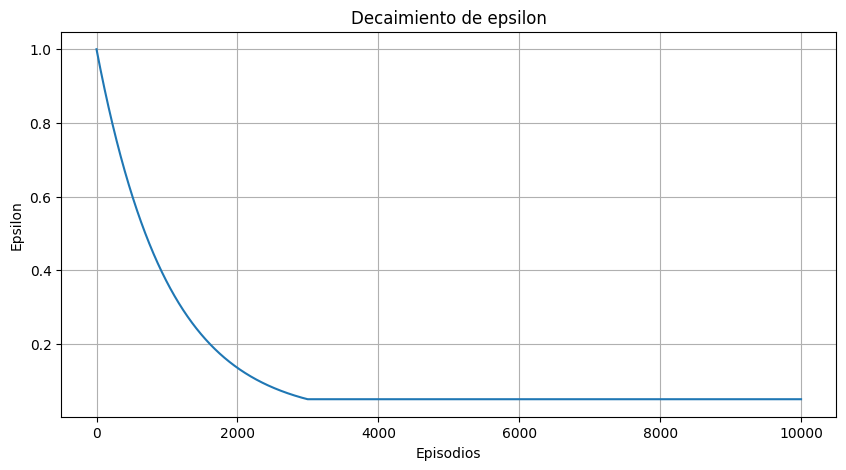

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(historial_epsilon)

plt.title(
    "Decaimiento de epsilon"
)

plt.xlabel("Episodios")
plt.ylabel("Epsilon")

plt.grid()

plt.show()

# **Actividad 9. Tabla Q final**

In [ ]:
acciones = [
    "Izquierda",
    "Abajo",
    "Derecha",
    "Arriba"
]

df_q = pd.DataFrame(
    tabla_q,
    columns=acciones
)

print(df_q.round(4))

    Izquierda   Abajo  Derecha  Arriba
0      0.7351  0.7738   0.7738  0.7351
1      0.7351  0.0000   0.8145  0.7738
2      0.7738  0.8574   0.7738  0.8145
3      0.8145  0.0000   0.7738  0.7732
4      0.7738  0.8145   0.0000  0.7351
5      0.0000  0.0000   0.0000  0.0000
6      0.0000  0.9025   0.0000  0.8145
7      0.0000  0.0000   0.0000  0.0000
8      0.8145  0.0000   0.8574  0.7738
9      0.8145  0.9025   0.9025  0.0000
10     0.8574  0.9500   0.0000  0.8574
11     0.0000  0.0000   0.0000  0.0000
12     0.0000  0.0000   0.0000  0.0000
13     0.0000  0.9025   0.9500  0.8574
14     0.9025  0.9500   1.0000  0.9025
15     0.0000  0.0000   0.0000  0.0000


# **Actividad 10. Política aprendida**

In [ ]:
simbolos = ["←","↓","→","↑"]

mapa = env.unwrapped.desc

politica = []

for estado in range(n_estados):

    fila, columna = divmod(
        estado,
        4
    )

    casilla = mapa[
        fila,
        columna
    ].decode("utf-8")

    if casilla in ["H","G"]:
        politica.append(casilla)

    else:
        mejor_accion = int(
            np.argmax(
                tabla_q[estado]
            )
        )

        politica.append(
            simbolos[mejor_accion]
        )

print("Politica aprendida")

for fila in range(4):
    inicio = fila * 4
    fin = inicio + 4

    print(
        " ".join(
            politica[inicio:fin]
        )
    )

Politica aprendida
↓ → ↓ ←
↓ H ↓ H
→ ↓ ↓ H
H → → G


# **Actividad 11. Evaluar agente**

In [ ]:
episodios_evaluacion = 1000

exitos = 0

pasos_exitosos = []

for episodio in range(
    episodios_evaluacion
):

    estado, info = env.reset()

    for paso in range(
        max_pasos
    ):

        accion = int(
            np.argmax(
                tabla_q[estado]
            )
        )

        nuevo_estado, recompensa, terminado, truncado, info = env.step(accion)

        estado = nuevo_estado

        if terminado or truncado:

            if recompensa == 1:
                exitos += 1
                pasos_exitosos.append(
                    paso + 1
                )

            break

tasa_exito = (
    exitos /
    episodios_evaluacion
)

promedio_pasos = (
    np.mean(
        pasos_exitosos
    )
)

print(
    "Tasa de exito:",
    tasa_exito
)

print(
    "Promedio pasos:",
    promedio_pasos
)

Tasa de exito: 1.0
Promedio pasos: 6.0


# **Actividad 12. Agente aleatorio**

In [ ]:
rng_eval = np.random.default_rng(123)

exitos_aleatorios = 0

for episodio in range(
    episodios_evaluacion
):

    estado, info = env.reset()

    for paso in range(
        max_pasos
    ):

        accion = int(
            rng_eval.integers(
                n_acciones
            )
        )

        estado, recompensa, terminado, truncado, info = env.step(accion)

        if terminado or truncado:

            if recompensa == 1:
                exitos_aleatorios += 1

            break

tasa_aleatoria = (
    exitos_aleatorios /
    episodios_evaluacion
)

print(
    "Aleatorio:",
    tasa_aleatoria
)

print(
    "Q-Learning:",
    tasa_exito
)

Aleatorio: 0.018
Q-Learning: 1.0


# **ACTIVIDAD EXTRA (RETO)**

In [ ]:
env_reto = gym.make(
    "FrozenLake-v1",
    map_name="4x4",
    is_slippery=True
)

tabla_q_reto = np.zeros(
    (16,4)
)

print(tabla_q_reto.shape)

(16, 4)
